# Preprocessing pipeline with sklearn

Chaining transformations into feature set, preprocessing transformations are applied one after another into sequential manner into train, test and validation set. It would mantain the model stability.

`sklearn.pipeline` Provides composing utilities for making composite estimators, chain of transformers

1. Pipeline : assemble sequence of transformer for sequential operation
2. FeatureUnion : Combines output of several transformation into one new transformer

`sklearn.pipeline` imports `Pipeline`
+ sequential application of transformers and estimators
+ intermediate must apply `fit_transform` final one with just fit
+ Makes easy cross validation with multiple transformations depended into some parameters tuning

In [63]:
# transformation demonstration
import pandas as pd 
import numpy as np

# Simple numerical generation for testing

SIZE = 100

latitudes = np.random.randint(
    low=-1000,
    high=1000,
    size=SIZE
)
longitude = np.random.randint(
    low=-1000,
    high=1000,
    size=SIZE
)

heights = np.linspace(
    100,0,SIZE
)
weights = pd.Series(np.linspace(
    100, 10000,SIZE
)).sample(SIZE)

data = {
    'geo_lat':latitudes,
    'geo_lon':longitude,
    'height':heights,
    'weights':weights
}

df = pd.DataFrame(data)

df

,geo_lat,geo_lon,height,weights
29,816,387,100.000000,3000.0
81,378,-991,98.989899,8200.0
6,413,-861,97.979798,700.0
10,109,176,96.969697,1100.0
12,405,180,95.959596,1300.0
...,...,...,...,...
65,-39,-399,4.040404,6600.0
53,435,652,3.030303,5400.0
95,-717,46,2.020202,9600.0
94,-559,-747,1.010101,9500.0


Shape config, (100, 1), with (100, 2)


<Axes: xlabel='geo_lat', ylabel='geo_lon'>

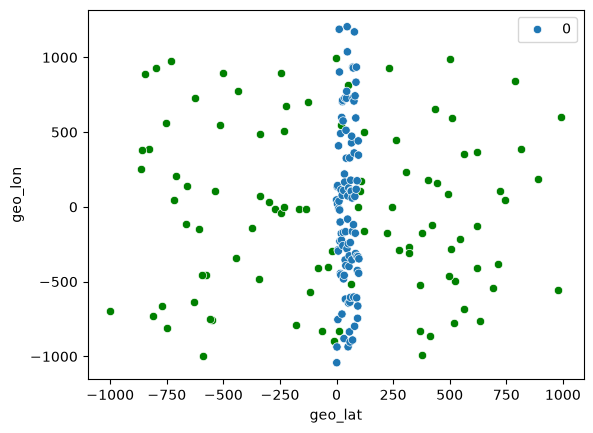

In [64]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA 

# we can also check the effect with using standard pca with dataset
X = df.loc[:, ['geo_lat', 'geo_lon']].copy(deep=True)

pca = PCA(n_components=1)
pca_elem = transf.fit_transform(X)

print(f'Shape config, {pca_elem.shape}, with {X.shape}')

sns.scatterplot(df, x='geo_lat', y='geo_lon', color='green')
sns.scatterplot(
    pca_elem
)

<Axes: ylabel='Density'>

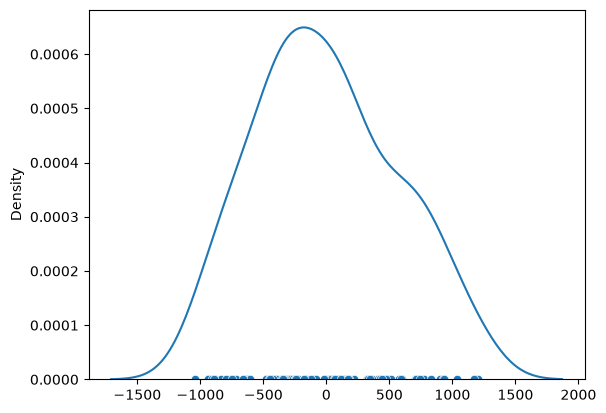

In [65]:
# kde plot with seaborn
import seaborn as sns

pca_elem = pca_elem.flatten()

sns.scatterplot(
    x=pca_elem,
    y=np.zeros(len(pca_elem)),
)
sns.kdeplot(pca_elem)  # I knew normals are not abnormal

(100, 1)


<Axes: ylabel='Count'>

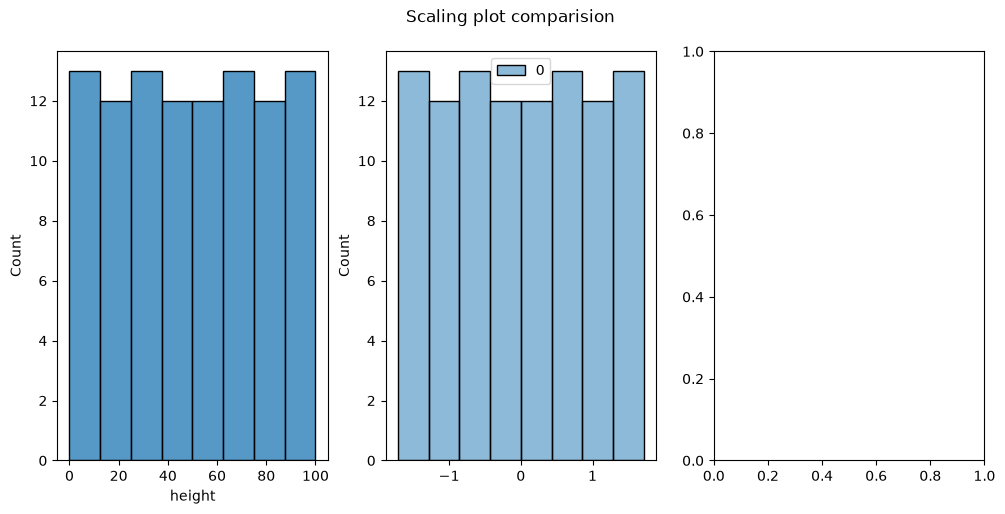

In [66]:
# Effect of numerical scalling with value
from sklearn.preprocessing import StandardScaler

fig, ax = plt.subplots(
    1,3,
    figsize=(10,5)
)
fig.suptitle('Scaling plot comparision')
fig.tight_layout()

sns.histplot(df['height'].copy(deep=True), ax=ax[0])

scale = StandardScaler()
target = np.array([df['height']]).T
print(target.shape)
height_transformed = scale.fit_transform(
        target,
    )

sns.histplot(
    height_transformed, 
    ax=ax[1]
)
